In [2]:
# import packages
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [3]:
out_path = Path("/home/maggy/PhD/WholeGenomeBisulphiteSequencing/RNAseq_pipeline/17_splicing/01_rMATS/")
out_dir = out_path / "output_24R_vs_A"

In [4]:

for files in out_dir.glob("*.txt"):
    print(files)

/home/maggy/PhD/WholeGenomeBisulphiteSequencing/RNAseq_pipeline/17_splicing/01_rMATS/output_24R_vs_A/SE.MATS.JCEC.txt
/home/maggy/PhD/WholeGenomeBisulphiteSequencing/RNAseq_pipeline/17_splicing/01_rMATS/output_24R_vs_A/MXE.MATS.JCEC.txt
/home/maggy/PhD/WholeGenomeBisulphiteSequencing/RNAseq_pipeline/17_splicing/01_rMATS/output_24R_vs_A/RI.MATS.JCEC.txt
/home/maggy/PhD/WholeGenomeBisulphiteSequencing/RNAseq_pipeline/17_splicing/01_rMATS/output_24R_vs_A/A5SS.MATS.JCEC.txt
/home/maggy/PhD/WholeGenomeBisulphiteSequencing/RNAseq_pipeline/17_splicing/01_rMATS/output_24R_vs_A/A3SS.MATS.JCEC.txt
/home/maggy/PhD/WholeGenomeBisulphiteSequencing/RNAseq_pipeline/17_splicing/01_rMATS/output_24R_vs_A/summary.txt


In [5]:
NvsA = [
    "ccar_ua02-g2350",
    "ccar_ua05-g5816",
    "ccar_ua10-g10025",
    "ccar_ua15-g14205",
    "ccar_ua15-g14343",
    "ccar_ua16-g15662",
    "ccar_ua18-g16750",
    "ccar_ub04-g26931",
    "ccar_ub09-g32086",
    "ccar_ub11-g34027",
    "ccar_ub12-g34297",
    "ccar_ub15-g36855",
    "ccar_ub22-g43219",
    "ccar_ub22-g43386",
]

NvsR = [
    "ccar_ua02-g1919",
    "ccar_ua05-g5120",
    "ccar_ua06-g6720",
    "ccar_ua11-g11397",
    "ccar_ua12-g11671",
    "ccar_ua14-g13591",
    "ccar_ua15-g14340",
    "ccar_ua15-g14373",
    "ccar_ua15-g14605",
    "ccar_ua16-g15290",
    "ccar_ua19-g18077",
    "ccar_ua22-g20613",
    "ccar_ua25-g22987",
    "ccar_ua25-g23230",
    "ccar_ub01-g23719",
    "ccar_ub03-g26528",
    "ccar_ub03-g26560",
    "ccar_ub05-g28395",
    "ccar_ub09-g32065",
    "ccar_ub11-g34058",
    "ccar_ub12-g34593",
    "ccar_ub14-g36416",
    "ccar_ub20-g41333",
    "ccar_ub21-g41935",
    "ccar_ub22-g43204",
    "ccar_ub22-g43390",
]

RvsA = [
    "ccar_ua05-g5369",
    "ccar_ua05-g5838",
    "ccar_ua09-g9070",
    "ccar_ua13-g12491",
    "ccar_ua20-g19122",
    "ccar_ua21-g19469",
    "ccar_ua23-g21428",
    "ccar_ua25-g22490",
    "ccar_ub10-g32303",
    "ccar_ub14-g36242",
    "ccar_ub19-g40403",
    "ccar_ub23-g43991",
    "ccar_ub25-g44776",
]


In [6]:
def data_import(file: Path, comparison: set, p_value: float = 0.05, allow_duplicates: bool = False) -> pd.DataFrame:
    """
    Import and filter data based on a comparison set.

    Parameters:
    file (Path): The path to the input file.
    comparison (set): A set of gene IDs to filter the data.
    p_value (float): The p-value threshold for filtering.
    allow_duplicates (bool): Whether to allow duplicate gene IDs in the output.
    """
    df = pd.read_csv(file, sep="\t")
    df = df.loc[df['GeneID'].isin(set(comparison))]
    df = df.loc[df['PValue'] < p_value]
    if not allow_duplicates:
        df = df.drop_duplicates(subset=['GeneID'])
    return df

In [7]:
data_import(out_dir / "SE.MATS.JCEC.txt", comparison=RvsA)

,ID,GeneID,geneSymbol,chr,strand,exonStart_0base,exonEnd,upstreamES,upstreamEE,downstreamES,...,SJC_SAMPLE_1,IJC_SAMPLE_2,SJC_SAMPLE_2,IncFormLen,SkipFormLen,PValue,FDR,IncLevel1,IncLevel2,IncLevelDifference
4230,4375,ccar_ub25-g44776,NaN,chrccar_ub25,+,2391089,2391283,2371062,2371173,2393217,...,"3,0,4,0","19,27,35,10","0,0,0,0",343,149,0.028017,0.443488,"0.879,1.0,0.695,1.0","1.0,1.0,1.0,1.0",-0.107
8101,8401,ccar_ua23-g21428,NaN,chrccar_ua23,+,15040060,15040116,15037812,15037975,15040244,...,"6,0,5,0","36,20,43,22","0,0,0,5",205,149,0.037362,0.528329,"0.858,1.0,0.734,1.0","1.0,1.0,1.0,0.762",-0.042
16806,17393,ccar_ua05-g5838,NaN,chrccar_ua05,-,27806600,27806666,27805401,27805446,27807487,...,"17,12,7,8","63,57,66,81","11,6,29,7",215,149,0.026313,0.429721,"0.856,0.883,0.919,0.847","0.799,0.868,0.612,0.889",0.084


In [8]:
def assess_splicing(folder: Path, comparison: set, p_value: float = 0.05, allow_duplicates: bool = False) -> dict:
    """
    Assess splicing events in a given folder based on a comparison set.

    Parameters:
    folder (Path): The path to the folder containing the splicing files.
    comparison (set): A set of gene IDs to filter the data.
    p_value (float): The p-value threshold for filtering.
    allow_duplicates (bool): Whether to allow duplicate gene IDs in the output.

    Returns:
    dict: A dictionary containing the filtered data for each splicing event type.
    """
    a3ss = data_import(folder / f"A3SS.MATS.JCEC.txt", comparison=comparison, p_value=p_value, allow_duplicates=allow_duplicates)
    a5ss = data_import(folder / f"A5SS.MATS.JCEC.txt", comparison=comparison, p_value=p_value, allow_duplicates=allow_duplicates)
    mxe = data_import(folder / f"MXE.MATS.JCEC.txt", comparison=comparison, p_value=p_value, allow_duplicates=allow_duplicates)
    ri = data_import(folder / f"RI.MATS.JCEC.txt", comparison=comparison, p_value=p_value, allow_duplicates=allow_duplicates)
    se = data_import(folder / f"SE.MATS.JCEC.txt", comparison=comparison, p_value=p_value, allow_duplicates=allow_duplicates)

    return {
        "a3ss": len(a3ss),
        "a5ss": len(a5ss),
        "mxe": len(mxe),
        "ri": len(ri),
        "se": len(se)
    }


In [9]:
assess_splicing(out_path / "output_24R_vs_A", comparison=RvsA, allow_duplicates=True)


{'a3ss': 0, 'a5ss': 0, 'mxe': 1, 'ri': 1, 'se': 3}

In [10]:
assess_splicing(out_path / "output_N_vs_A", comparison=NvsA, allow_duplicates=True)

{'a3ss': 0, 'a5ss': 0, 'mxe': 0, 'ri': 0, 'se': 2}

In [11]:
assess_splicing(out_path / "output_N_vs_24R", comparison=NvsR, allow_duplicates=True)

{'a3ss': 1, 'a5ss': 0, 'mxe': 0, 'ri': 2, 'se': 3}

In [12]:
splicing_events = assess_splicing(out_path / "output_N_vs_24R", comparison=NvsR)

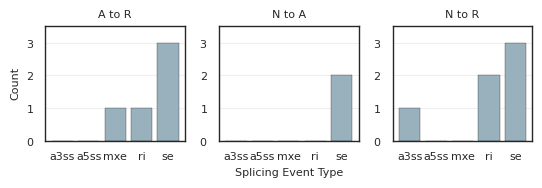

In [13]:
# Set theme and figure style
sns.set_theme(style='white', context='paper', rc={'axes.labelsize':8, 'xtick.labelsize':8, 'ytick.labelsize':8, 'legend.fontsize':8, 'legend.title_fontsize':8, "axes.formatter.use_mathtext": True})

# Create bar plots for all three comparisons in a grid
splicing_RvsA = assess_splicing(out_path / "output_24R_vs_A", comparison=RvsA, allow_duplicates=True)
splicing_NvsA = assess_splicing(out_path / "output_N_vs_A", comparison=NvsA, allow_duplicates=True)
splicing_NvsR = assess_splicing(out_path / "output_N_vs_24R", comparison=NvsR, allow_duplicates=True)

# Create a 1x3 grid of bar plots
fig, axes = plt.subplots(1, 3, figsize=((14)/2.54, (5/2.54)))

comparisons = {
    'A to R': splicing_RvsA,
    'N to A': splicing_NvsA,
    'N to R': splicing_NvsR
}

# Find the maximum count across all comparisons to use the same y-axis scale
max_count = max(max(counts for counts in comp.values()) for comp in comparisons.values())

for idx, (comparison_name, splicing_data) in enumerate(comparisons.items()):
    ax = axes[idx]
    events = list(splicing_data.keys())
    counts = list(splicing_data.values())
    
    ax.bar(events, counts, color='#99B1BD', edgecolor='black', linewidth=0.2)
    ax.set_ylim(0, max_count + 0.5)  # Set same y-axis scale for all
    
    # Only show x-axis label once (on the middle subplot)
    if idx == 1:
        ax.set_xlabel('Splicing Event Type', fontsize=8)
    
    # Only show y-axis label on the first subplot
    if idx == 0:
        ax.set_ylabel('Count', fontsize=8)
    
    ax.set_title(f'{comparison_name}', fontsize=8)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig("dmr_splicing_events.png", dpi=500)
plt.show()